# Tarea 2, Pregunta 1: Regresión lineal y regresión logística

Para esta pregunta usamos el dataset *Default of Credit Card Clients* del repositorio UCI. Reúne a 30.000 clientes de un banco de Taiwán en 2005 y, para cada uno, 23 atributos con su perfil, su historial de pagos, los montos facturados y los montos pagados, además de una etiqueta que indica si cayó en impago al mes siguiente. Con más de 20.000 filas y más de 12 columnas utilizables, cumple los requisitos del enunciado.

El objetivo es resolver dos problemas sobre los mismos datos: predecir una variable continua $Y_1$ con regresión lineal y una variable binaria $Y_2$ con regresión logística. Ambos modelos usan las mismas diez variables predictoras $X_1, \dots, X_{10}$, y de cada uno entrenamos tres versiones: con las diez variables, con las cinco más relevantes y con las tres más relevantes. La selección de variables se hace solo con el conjunto de entrenamiento. Las tres versiones se comparan en entrenamiento y validación, y solo las dos mejores de cada tarea llegan al conjunto de prueba. Con eso analizamos si aparece overfitting o underfitting al cambiar la cantidad de variables.

El notebook sigue este orden:

1. Carga, limpieza y definición de las variables.
2. División en 70 % entrenamiento, 15 % validación y 15 % prueba, la misma para ambas tareas.
3. Selección de variables con *forward selection* y validación cruzada dentro del entrenamiento.
4. Entrenamiento y comparación de las tres versiones de cada modelo.
5. Evaluación en prueba de las dos mejores versiones.
6. Análisis del efecto de la cantidad de variables sobre el desempeño y la generalización.

## 1. Librerías y configuración

Fijamos una semilla al inicio para que todos los resultados del notebook sean reproducibles.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
)

warnings.filterwarnings('ignore', category=FutureWarning)

SEED = 42
np.random.seed(SEED)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
plt.rcParams['figure.dpi'] = 110

## 2. Carga de datos

El archivo `.xls` original trae dos filas de encabezado: la primera con los códigos `X1 ... X23, Y` y la segunda con los nombres reales de las columnas. Por eso lo leemos con `header=1`. Para abrir archivos `.xls`, pandas necesita la librería `xlrd`.

In [ ]:
RUTA_DATOS = 'Datasets/default of credit card clients.xls'

df_raw = pd.read_excel(RUTA_DATOS, header=1)
df_raw = df_raw.rename(columns={'default payment next month': 'DEFAULT'})

print('Dimensiones:', df_raw.shape)
print('Valores nulos totales:', int(df_raw.isna().sum().sum()))
print('Filas duplicadas (sin contar ID):', int(df_raw.drop(columns=['ID']).duplicated().sum()))
df_raw.head()

El dataset no tiene valores nulos. Sí aparecen 35 filas duplicadas, pero no son errores de registro: corresponden a clientes distintos, con `ID` diferente, que coinciden en todos sus atributos. Casi todos son clientes sin facturación ni pagos, con todos los montos en cero, así que es natural que se repitan. Como son clientes reales, los mantenemos.

### Descripción de las columnas

El cuadro resume el significado de cada columna según la documentación de UCI.

| Columna | Descripción |
|---|---|
| `ID` | Identificador del cliente (no se usa) |
| `LIMIT_BAL` | Monto del crédito otorgado (dólares NT), incluye crédito individual y familiar |
| `SEX` | 1 = hombre, 2 = mujer |
| `EDUCATION` | 1 = postgrado, 2 = universitaria, 3 = secundaria, 4 = otros (0, 5 y 6 no documentados) |
| `MARRIAGE` | 1 = casado, 2 = soltero, 3 = otros (0 no documentado) |
| `AGE` | Edad en años |
| `PAY_0`, `PAY_2` ... `PAY_6` | Estado de pago en septiembre, agosto, ..., abril. -1 = pagó a tiempo, 1 = un mes de atraso, 2 = dos meses, etc. (-2 y 0 indican sin consumo o pago mínimo) |
| `BILL_AMT1` ... `BILL_AMT6` | Monto facturado de septiembre a abril |
| `PAY_AMT1` ... `PAY_AMT6` | Monto pagado de septiembre a abril |
| `DEFAULT` | 1 = el cliente cae en impago el mes siguiente, 0 = no |

## 3. Definición de variables objetivo y predictoras

Como variable continua $Y_1$ elegimos `LIMIT_BAL`, el cupo de crédito que el banco le asigna a cada cliente. El problema de regresión consiste en estimar qué cupo le corresponde a un cliente a partir de su perfil y de su comportamiento reciente de facturación y pago. Es una variable continua con un rango amplio, que va desde 10.000 hasta 1.000.000.

Como variable binaria $Y_2$ usamos `DEFAULT`, que indica si el cliente cae en impago el mes siguiente. Es la etiqueta original del dataset y un problema clásico de clasificación binaria.

Las diez variables predictoras son las mismas en ambas tareas, y las elegimos para cubrir los tres tipos de información que trae el dataset:

| # | Variable | Grupo | Tratamiento |
|---|---|---|---|
| X1 | `SEX` | Perfil | Se recodifica a 0 = hombre, 1 = mujer |
| X2 | `EDUCATION` | Perfil | Los códigos 0, 5 y 6 (no documentados) se agrupan en 4 = otros. Se trata como ordinal |
| X3 | `MARRIED` | Perfil | `MARRIAGE` es nominal, se convierte en indicador 1 = casado, 0 = otro |
| X4 | `AGE` | Perfil | Sin cambios |
| X5 | `PAY_0` | Historial de pago | Estado de pago del mes más reciente |
| X6 | `PAY_2` | Historial de pago | Estado de pago del mes anterior |
| X7 | `BILL_AMT1` | Facturación | Monto facturado del mes más reciente |
| X8 | `BILL_AMT2` | Facturación | Monto facturado del mes anterior |
| X9 | `PAY_AMT1` | Pagos | Monto pagado del mes más reciente |
| X10 | `PAY_AMT2` | Pagos | Monto pagado del mes anterior |

Para llegar a esta lista seguimos cuatro criterios. Primero, de cada serie mensual (estado de pago, facturación y pagos) tomamos solo los dos meses más recientes, porque son los que reflejan el comportamiento actual del cliente y permiten quedarse en diez variables sin perder ningún tipo de información. Los meses más antiguos están muy correlacionados con los recientes y aportarían poco. Segundo, incluimos el perfil demográfico, que podría influir tanto en el cupo asignado como en el riesgo. Tercero, dejamos fuera las columnas que no pueden ser predictoras: `ID` es un identificador y `LIMIT_BAL` es $Y_1$, así que, como las variables deben ser las mismas en las dos tareas, tampoco la usamos para predecir $Y_2$. Por la misma razón `DEFAULT` no entra en la regresión. Cuarto, dejamos a propósito pares de variables correlacionadas, como `BILL_AMT1` y `BILL_AMT2`, para comprobar si la selección de variables es capaz de detectar la información redundante.

In [3]:
df = df_raw.drop(columns=['ID']).copy()

# EDUCATION: los codigos 0, 5 y 6 no estan documentados, se agrupan en 4 (otros)
df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4})

# SEX: 1 = hombre, 2 = mujer  ->  0 = hombre, 1 = mujer
df['SEX'] = (df['SEX'] == 2).astype(int)

# MARRIAGE es nominal, se transforma en un indicador binario (1 = casado)
df['MARRIED'] = (df['MARRIAGE'] == 1).astype(int)

Y1 = 'LIMIT_BAL'
Y2 = 'DEFAULT'
PREDICTORAS = ['SEX', 'EDUCATION', 'MARRIED', 'AGE',
               'PAY_0', 'PAY_2',
               'BILL_AMT1', 'BILL_AMT2',
               'PAY_AMT1', 'PAY_AMT2']

data = df[PREDICTORAS + [Y1, Y2]]
print('Dimensiones del conjunto de trabajo:', data.shape)
data.describe().T

Dimensiones del conjunto de trabajo: (30000, 12)


,count,mean,std,min,25%,50%,75%,max
SEX,"30,000.0000",0.6037,0.4891,0.0000,0.0000,1.0000,1.0000,1.0000
EDUCATION,"30,000.0000",1.8423,0.7445,1.0000,1.0000,2.0000,2.0000,4.0000
MARRIED,"30,000.0000",0.4553,0.4980,0.0000,0.0000,0.0000,1.0000,1.0000
AGE,"30,000.0000",35.4855,9.2179,21.0000,28.0000,34.0000,41.0000,79.0000
PAY_0,"30,000.0000",-0.0167,1.1238,-2.0000,-1.0000,0.0000,0.0000,8.0000
PAY_2,"30,000.0000",-0.1338,1.1972,-2.0000,-1.0000,0.0000,0.0000,8.0000
BILL_AMT1,"30,000.0000","51,223.3309","73,635.8606","-165,580.0000","3,558.7500","22,381.5000","67,091.0000","964,511.0000"
BILL_AMT2,"30,000.0000","49,179.0752","71,173.7688","-69,777.0000","2,984.7500","21,200.0000","64,006.2500","983,931.0000"
PAY_AMT1,"30,000.0000","5,663.5805","16,563.2804",0.0000,"1,000.0000","2,100.0000","5,006.0000","873,552.0000"
PAY_AMT2,"30,000.0000","5,921.1635","23,040.8704",0.0000,833.0000,"2,009.0000","5,000.0000","1,684,259.0000"


## 4. División en entrenamiento, validación y prueba

Hacemos una sola división, compartida por ambas tareas: 70 % entrenamiento, 15 % validación y 15 % prueba. Primero separamos el 70 % de entrenamiento y después dividimos el 30 % restante en dos mitades iguales.

La división está estratificada según `DEFAULT`, porque las clases están desbalanceadas: cerca del 22 % de los clientes cae en impago. Así los tres conjuntos mantienen la misma proporción de clases, como se ve en la tabla de abajo. La semilla queda fija para que los resultados sean reproducibles.

In [4]:
X = data[PREDICTORAS]
y1 = data[Y1]
y2 = data[Y2]

X_train, X_temp, y1_train, y1_temp, y2_train, y2_temp = train_test_split(
    X, y1, y2, test_size=0.30, stratify=y2, random_state=SEED)

X_val, X_test, y1_val, y1_test, y2_val, y2_test = train_test_split(
    X_temp, y1_temp, y2_temp, test_size=0.50, stratify=y2_temp, random_state=SEED)

resumen_split = pd.DataFrame({
    'Filas': [len(X_train), len(X_val), len(X_test)],
    'Porcentaje': [len(X_train) / len(X), len(X_val) / len(X), len(X_test) / len(X)],
    'Media LIMIT_BAL': [y1_train.mean(), y1_val.mean(), y1_test.mean()],
    'Tasa DEFAULT': [y2_train.mean(), y2_val.mean(), y2_test.mean()],
}, index=['Entrenamiento', 'Validacion', 'Prueba'])
resumen_split

,Filas,Porcentaje,Media LIMIT_BAL,Tasa DEFAULT
Entrenamiento,21000,0.7000,"167,499.1429",0.2212
Validacion,4500,0.1500,"166,086.6667",0.2211
Prueba,4500,0.1500,"168,812.8178",0.2213


## 5. Exploración del conjunto de entrenamiento

Exploramos solo el conjunto de entrenamiento, para que ninguna decisión posterior use información de validación o de prueba.

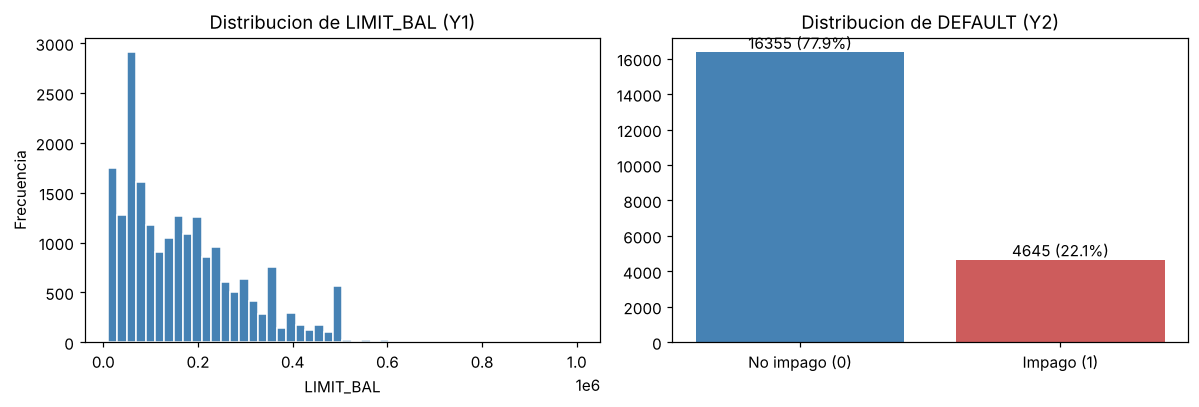

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].hist(y1_train, bins=50, color='steelblue', edgecolor='white')
axes[0].set_title('Distribucion de LIMIT_BAL (Y1)')
axes[0].set_xlabel('LIMIT_BAL')
axes[0].set_ylabel('Frecuencia')

conteo = y2_train.value_counts().sort_index()
axes[1].bar(['No impago (0)', 'Impago (1)'], conteo.values, color=['steelblue', 'indianred'])
for i, v in enumerate(conteo.values):
    axes[1].text(i, v, f'{v} ({v / conteo.sum():.1%})', ha='center', va='bottom')
axes[1].set_title('Distribucion de DEFAULT (Y2)')

plt.tight_layout()
plt.show()

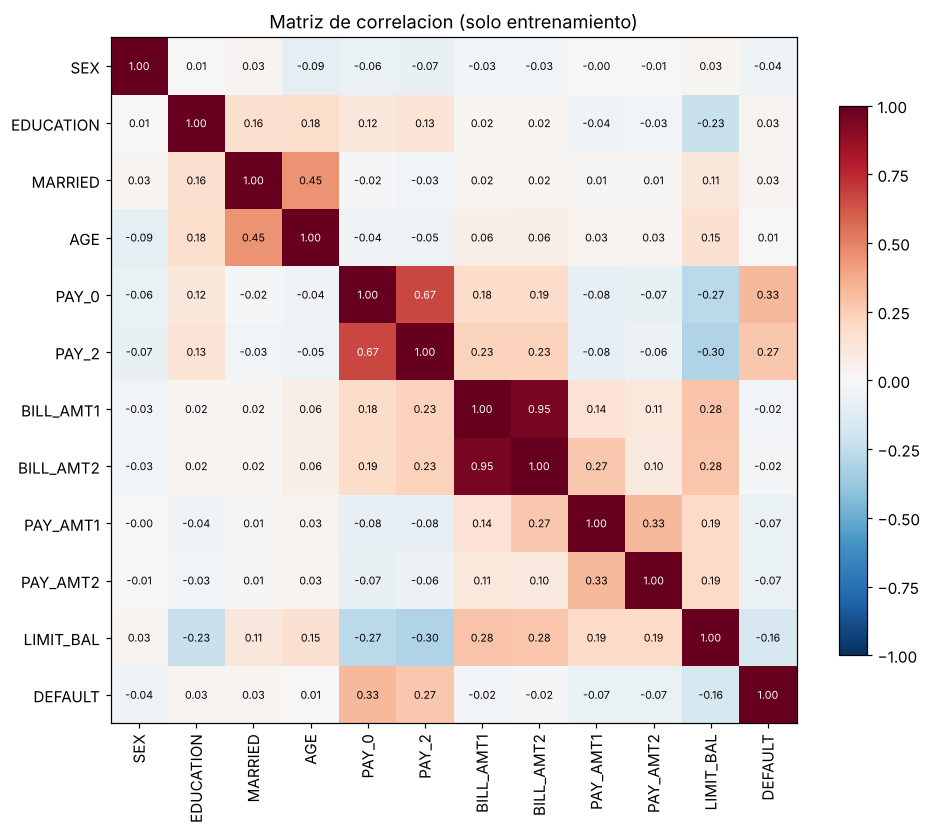

In [6]:
corr = pd.concat([X_train, y1_train, y2_train], axis=1).corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7,
                color='white' if abs(corr.iloc[i, j]) > 0.6 else 'black')
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title('Matriz de correlacion (solo entrenamiento)')
plt.tight_layout()
plt.show()

De la matriz de correlación sacamos dos observaciones que importan para la selección de variables. La primera es que hay pares muy correlacionados entre sí, como `BILL_AMT1` con `BILL_AMT2` y `PAY_0` con `PAY_2`. Si eligiéramos las variables solo por su correlación con el objetivo, probablemente nos quedaríamos con las dos de cada par, aunque la segunda aporte poca información nueva. La segunda es que las correlaciones con $Y_1$ y con $Y_2$ son bastante distintas, así que es esperable que las variables más relevantes no sean las mismas en las dos tareas.

## 6. Método de selección de variables

Para ordenar las variables usamos selección secuencial hacia adelante (*forward selection*) con validación cruzada de 5 folds sobre el conjunto de entrenamiento. El procedimiento parte sin variables y, en cada paso, prueba agregar cada una de las que faltan y mide el desempeño promedio de la validación cruzada. La variable que más mejora la métrica se incorpora al modelo, y el proceso se repite hasta ordenar las diez. El resultado es un ranking: las tres más relevantes son las tres primeras y las cinco más relevantes son las cinco primeras, por lo que los subconjuntos quedan anidados.

Elegimos este método por tres razones:

- Usa solo datos de entrenamiento, como exige el enunciado. Validación y prueba no participan en la selección.
- A diferencia de un ranking por correlación, mide cuánto aporta cada variable dado lo que ya está en el modelo, así que tiende a evitar las variables redundantes.
- La selección se hace con el mismo tipo de modelo que después se entrena, por lo que es coherente con cada tarea.

La métrica de selección depende de la tarea. En la regresión lineal usamos $R^2$, que equivale a minimizar el error cuadrático medio, es decir, la función de costo $J(\theta)$ de la regresión lineal. En la regresión logística usamos ROC-AUC, porque no depende del umbral de decisión y es robusta al desbalance de clases. El accuracy habría sido engañoso: un modelo que siempre predice "no impago" tendría cerca de 78 % de accuracy sin haber aprendido nada.

Sobre los modelos hay que tener en cuenta tres detalles. Ambos se entrenan dentro de un *pipeline* con `StandardScaler`, que se ajusta solo con los datos de cada fold de entrenamiento, de modo que no se filtra información de los folds de validación. `LinearRegression` minimiza la misma función de costo vista en clases, pero la resuelve de forma cerrada en vez de usar gradiente descendente. `LogisticRegression` minimiza la función de costo logística (log-loss) con regularización L2 y `C = 1`, la opción por defecto, que corresponde al término de regularización visto en la clase 14. Además usamos `class_weight='balanced'` para que el modelo no ignore la clase minoritaria, que en este problema es justamente la que interesa detectar.

In [7]:
def crear_modelo_regresion():
    return make_pipeline(StandardScaler(), LinearRegression())


def crear_modelo_clasificacion():
    return make_pipeline(StandardScaler(),
                         LogisticRegression(class_weight='balanced', max_iter=1000))


def seleccion_forward(X, y, crear_modelo, scoring, cv):
    # Ordena todas las variables agregando en cada paso la que mas mejora el score de CV
    restantes = list(X.columns)
    elegidas = []
    historial = []
    while restantes:
        puntajes = {}
        for var in restantes:
            cols = elegidas + [var]
            puntajes[var] = cross_val_score(crear_modelo(), X[cols], y,
                                            scoring=scoring, cv=cv).mean()
        mejor = max(puntajes, key=puntajes.get)
        elegidas.append(mejor)
        restantes.remove(mejor)
        historial.append({'Paso': len(elegidas),
                          'Variable agregada': mejor,
                          f'{scoring} CV (5 folds)': puntajes[mejor]})
    return elegidas, pd.DataFrame(historial).set_index('Paso')


def metricas_regresion(y_true, y_pred):
    return {'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'MAE': mean_absolute_error(y_true, y_pred),
            'R2': r2_score(y_true, y_pred)}


def metricas_clasificacion(y_true, y_pred, y_prob):
    return {'Accuracy': accuracy_score(y_true, y_pred),
            'Precision': precision_score(y_true, y_pred, zero_division=0),
            'Recall': recall_score(y_true, y_pred),
            'F1': f1_score(y_true, y_pred),
            'ROC_AUC': roc_auc_score(y_true, y_prob)}


def graficar_curva_seleccion(historial, titulo, etiqueta):
    col = historial.columns[-1]
    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.plot(historial.index, historial[col], marker='o')
    for k in (3, 5):
        ax.axvline(k, color='gray', ls='--', lw=0.8)
        ax.text(k, ax.get_ylim()[0], f' {k} var.', color='gray', va='bottom')
    ax.set_xticks(historial.index, [f'{i}\n{v}' for i, v in historial['Variable agregada'].items()],
                  fontsize=7)
    ax.set_ylabel(etiqueta)
    ax.set_title(titulo)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

---
# Tarea A: Regresión lineal para predecir `LIMIT_BAL` ($Y_1$)

## A.1 Selección de variables (solo entrenamiento)

Junto al ranking de *forward selection* calculamos la correlación absoluta de cada variable con $Y_1$. Ese segundo ranking no se usa para elegir nada; sirve solo como referencia para ver en qué se diferencian ambos criterios.

In [8]:
orden_reg, hist_reg = seleccion_forward(X_train, y1_train, crear_modelo_regresion,
                                        scoring='r2', cv=cv_reg)

# Ranking por correlacion absoluta con Y1, solo como referencia para comparar
corr_y1 = X_train.corrwith(y1_train).abs().sort_values(ascending=False)

hist_reg['|corr| con Y1 de la variable'] = hist_reg['Variable agregada'].map(corr_y1)
hist_reg['Ranking por |corr|'] = hist_reg['Variable agregada'].map(
    {v: i + 1 for i, v in enumerate(corr_y1.index)})

print('Top 5 por forward selection:', orden_reg[:5])
print('Top 3 por forward selection:', orden_reg[:3])
print('Top 5 por correlacion      :', list(corr_y1.index[:5]))
hist_reg

Top 5 por forward selection: ['PAY_2', 'BILL_AMT1', 'EDUCATION', 'AGE', 'PAY_AMT2']
Top 3 por forward selection: ['PAY_2', 'BILL_AMT1', 'EDUCATION']
Top 5 por correlacion      : ['PAY_2', 'BILL_AMT1', 'BILL_AMT2', 'PAY_0', 'EDUCATION']


,Variable agregada,r2 CV (5 folds),|corr| con Y1 de la variable,Ranking por |corr|
Paso,,,,
1,PAY_2,0.0898,0.3005,1
2,BILL_AMT1,0.2229,0.2848,2
3,EDUCATION,0.2566,0.2258,5
4,AGE,0.2783,0.1507,8
5,PAY_AMT2,0.2891,0.1940,6
6,PAY_0,0.2975,0.2687,4
7,MARRIED,0.3016,0.1098,9
8,PAY_AMT1,0.3031,0.1928,7
9,SEX,0.3036,0.0300,10


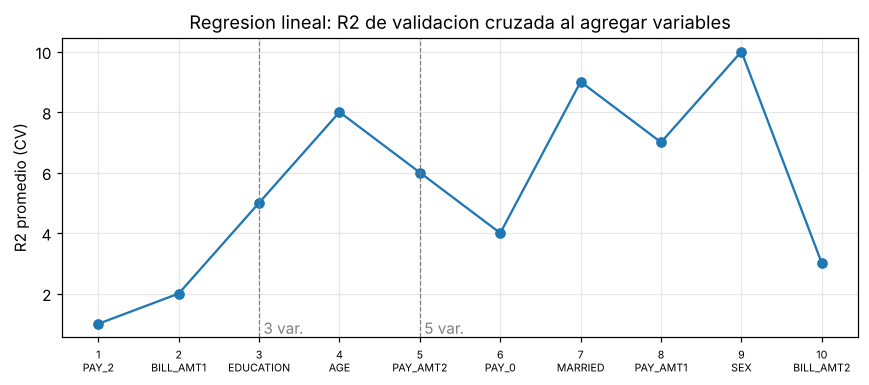

In [9]:
graficar_curva_seleccion(hist_reg, 'Regresion lineal: R2 de validacion cruzada al agregar variables',
                         'R2 promedio (CV)')

La tabla muestra el orden en que entraron las variables y el $R^2$ promedio de validación cruzada alcanzado en cada paso. La columna "Ranking por |corr|" permite compararlo con una selección ingenua por correlación, y la diferencia más clara está en `BILL_AMT2`. Es la tercera variable más correlacionada con $Y_1$, pero *forward selection* la deja en el último lugar: una vez que `BILL_AMT1` está en el modelo, su pareja casi no agrega información, e incluso al incorporarla el $R^2$ de validación cruzada baja levemente, de 0,3036 a 0,3033.

La curva también muestra que la mejora se concentra en las primeras variables. Con tres se llega a un $R^2$ de 0,26 y con cinco a 0,29, mientras que las últimas cinco suman apenas 0,014.

## A.2 Entrenamiento de las tres versiones y comparación en entrenamiento y validación

Entrenamos las tres versiones con el conjunto de entrenamiento completo y las medimos en entrenamiento y validación con RMSE, MAE y $R^2$. La última columna muestra la brecha de $R^2$ entre ambos conjuntos, que es la señal que usamos para detectar overfitting.

In [10]:
versiones_reg = {
    '10 variables': PREDICTORAS,
    '5 variables': orden_reg[:5],
    '3 variables': orden_reg[:3],
}

modelos_reg = {}
filas = []
for nombre, cols in versiones_reg.items():
    modelo = crear_modelo_regresion().fit(X_train[cols], y1_train)
    modelos_reg[nombre] = modelo
    for conjunto, Xc, yc in [('Entrenamiento', X_train, y1_train), ('Validacion', X_val, y1_val)]:
        filas.append({'Version': nombre, 'Conjunto': conjunto,
                      **metricas_regresion(yc, modelo.predict(Xc[cols]))})

res_reg = pd.DataFrame(filas)
tabla_reg = res_reg.pivot(index='Version', columns='Conjunto', values=['RMSE', 'MAE', 'R2'])
tabla_reg = tabla_reg.loc[list(versiones_reg)]
tabla_reg[('R2', 'Brecha (train - val)')] = tabla_reg[('R2', 'Entrenamiento')] - tabla_reg[('R2', 'Validacion')]

for nombre, cols in versiones_reg.items():
    print(f'{nombre}: {cols}')
tabla_reg

10 variables: ['SEX', 'EDUCATION', 'MARRIED', 'AGE', 'PAY_0', 'PAY_2', 'BILL_AMT1', 'BILL_AMT2', 'PAY_AMT1', 'PAY_AMT2']
5 variables: ['PAY_2', 'BILL_AMT1', 'EDUCATION', 'AGE', 'PAY_AMT2']
3 variables: ['PAY_2', 'BILL_AMT1', 'EDUCATION']


RMSE                        MAE              \
Conjunto     Entrenamiento   Validacion Entrenamiento  Validacion   
Version                                                             
10 variables  107,682.4873 107,252.5034   82,877.9693 82,908.0408   
5 variables   109,018.8681 109,062.1151   84,160.0120 84,416.3110   
3 variables   111,847.4706 111,275.7528   86,616.4477 86,691.1485   

                        R2                                  
Conjunto     Entrenamiento Validacion Brecha (train - val)  
Version                                                     
10 variables        0.3114     0.3025               0.0089  
5 variables         0.2942     0.2788               0.0154  
3 variables         0.2571     0.2492               0.0079

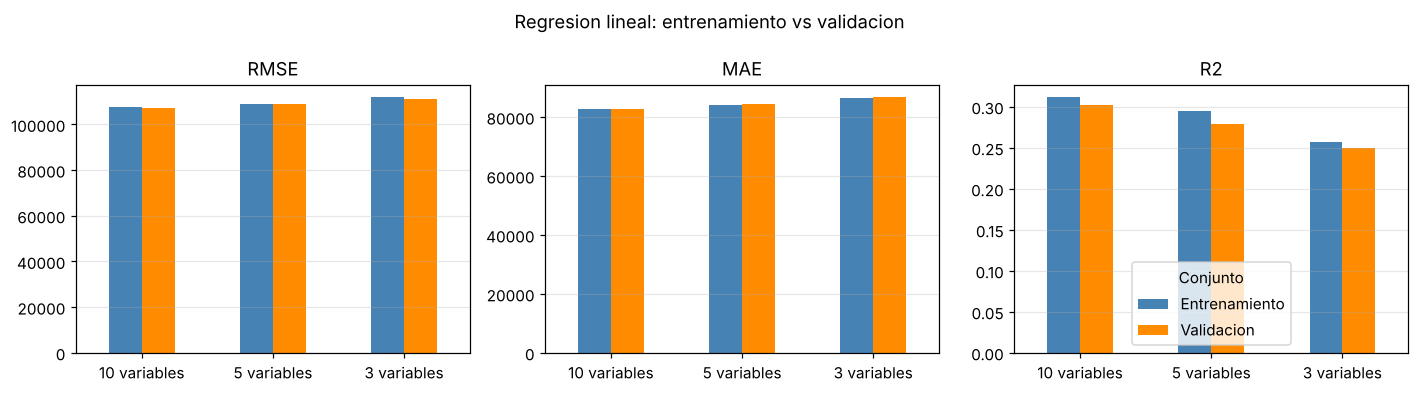

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, met in zip(axes, ['RMSE', 'MAE', 'R2']):
    piv = res_reg.pivot(index='Version', columns='Conjunto', values=met).loc[list(versiones_reg)]
    piv.plot(kind='bar', ax=ax, rot=0, color=['steelblue', 'darkorange'], legend=(met == 'R2'))
    ax.set_title(met)
    ax.set_xlabel('')
    ax.grid(axis='y', alpha=0.3)
plt.suptitle('Regresion lineal: entrenamiento vs validacion')
plt.tight_layout()
plt.show()

In [12]:
coef_reg = pd.DataFrame({
    nombre: pd.Series(modelo[-1].coef_, index=versiones_reg[nombre])
    for nombre, modelo in modelos_reg.items()
}).loc[PREDICTORAS]
print('Coeficientes estandarizados (cambio en LIMIT_BAL por una desviacion estandar de cada variable):')
coef_reg

Coeficientes estandarizados (cambio en LIMIT_BAL por una desviacion estandar de cada variable):


,10 variables,5 variables,3 variables
SEX,"3,325.1729",NaN,NaN
EDUCATION,"-27,583.3785","-27,331.9586","-24,059.2502"
MARRIED,"9,142.5839",NaN,NaN
AGE,"15,264.2362","19,189.7708",NaN
PAY_0,"-15,629.7576",NaN,NaN
PAY_2,"-32,385.0007","-43,806.0198","-47,029.0555"
BILL_AMT1,"43,076.7452","44,910.2394","48,431.5761"
BILL_AMT2,"1,338.0757",NaN,NaN
PAY_AMT1,"8,667.9373",NaN,NaN
PAY_AMT2,"13,036.3769","16,265.6797",NaN


## A.3 Evaluación en prueba de las dos mejores versiones

Elegimos las dos mejores versiones según el $R^2$ de validación, lo que equivale a elegir las de menor RMSE. El conjunto de prueba se usa solo en este paso.

In [13]:
val_reg = res_reg[res_reg['Conjunto'] == 'Validacion'].set_index('Version')
mejores_reg = val_reg.sort_values('R2', ascending=False).index[:2].tolist()
print('Dos mejores versiones en validacion:', mejores_reg)

filas = []
for nombre in mejores_reg:
    cols = versiones_reg[nombre]
    filas.append({'Version': nombre,
                  **metricas_regresion(y1_test, modelos_reg[nombre].predict(X_test[cols]))})
test_reg = pd.DataFrame(filas).set_index('Version')
test_reg

Dos mejores versiones en validacion: ['10 variables', '5 variables']


,RMSE,MAE,R2
Version,,,
10 variables,"109,059.2766","84,281.1953",0.3065
5 variables,"111,187.5954","85,740.8201",0.2791


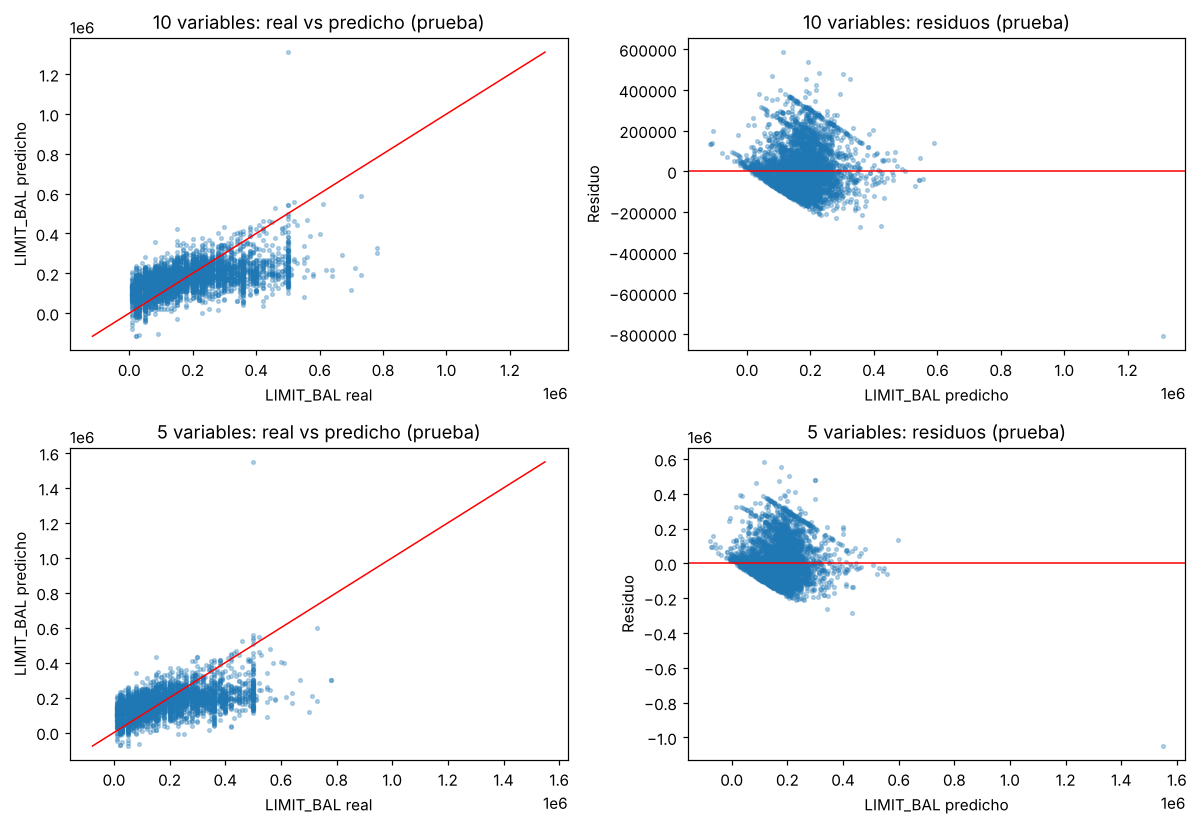

In [14]:
fig, axes = plt.subplots(len(mejores_reg), 2, figsize=(11, 3.8 * len(mejores_reg)))
for fila, nombre in zip(np.atleast_2d(axes), mejores_reg):
    cols = versiones_reg[nombre]
    pred = modelos_reg[nombre].predict(X_test[cols])
    res = y1_test - pred

    fila[0].scatter(y1_test, pred, s=6, alpha=0.3)
    lim = [min(y1_test.min(), pred.min()), max(y1_test.max(), pred.max())]
    fila[0].plot(lim, lim, color='red', lw=1)
    fila[0].set_xlabel('LIMIT_BAL real')
    fila[0].set_ylabel('LIMIT_BAL predicho')
    fila[0].set_title(f'{nombre}: real vs predicho (prueba)')

    fila[1].scatter(pred, res, s=6, alpha=0.3)
    fila[1].axhline(0, color='red', lw=1)
    fila[1].set_xlabel('LIMIT_BAL predicho')
    fila[1].set_ylabel('Residuo')
    fila[1].set_title(f'{nombre}: residuos (prueba)')
plt.tight_layout()
plt.show()

---
# Tarea B: Regresión logística para predecir `DEFAULT` ($Y_2$)

## B.1 Selección de variables (solo entrenamiento)

Repetimos el mismo procedimiento, ahora con ROC-AUC como métrica y con folds estratificados, para que cada uno mantenga la proporción de impagos.

In [15]:
orden_clf, hist_clf = seleccion_forward(X_train, y2_train, crear_modelo_clasificacion,
                                        scoring='roc_auc', cv=cv_clf)

corr_y2 = X_train.corrwith(y2_train).abs().sort_values(ascending=False)
hist_clf['|corr| con Y2 de la variable'] = hist_clf['Variable agregada'].map(corr_y2)
hist_clf['Ranking por |corr|'] = hist_clf['Variable agregada'].map(
    {v: i + 1 for i, v in enumerate(corr_y2.index)})

print('Top 5 por forward selection:', orden_clf[:5])
print('Top 3 por forward selection:', orden_clf[:3])
print('Top 5 por correlacion      :', list(corr_y2.index[:5]))
hist_clf

Top 5 por forward selection: ['PAY_0', 'PAY_AMT2', 'PAY_2', 'BILL_AMT1', 'PAY_AMT1']
Top 3 por forward selection: ['PAY_0', 'PAY_AMT2', 'PAY_2']
Top 5 por correlacion      : ['PAY_0', 'PAY_2', 'PAY_AMT1', 'PAY_AMT2', 'SEX']


,Variable agregada,roc_auc CV (5 folds),|corr| con Y2 de la variable,Ranking por |corr|
Paso,,,,
1,PAY_0,0.6925,0.3274,1
2,PAY_AMT2,0.7110,0.0666,4
3,PAY_2,0.7146,0.2678,2
4,BILL_AMT1,0.7180,0.0249,8
5,PAY_AMT1,0.7186,0.0701,3
6,BILL_AMT2,0.7199,0.0198,9
7,SEX,0.7198,0.0426,5
8,MARRIED,0.7201,0.0256,7
9,AGE,0.7198,0.0074,10


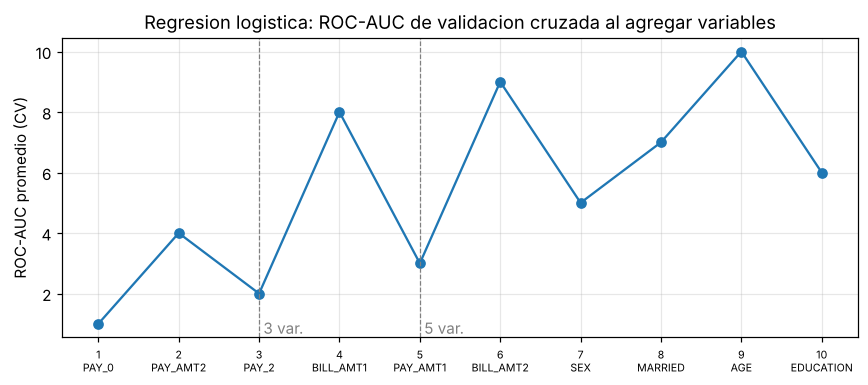

In [16]:
graficar_curva_seleccion(hist_clf, 'Regresion logistica: ROC-AUC de validacion cruzada al agregar variables',
                         'ROC-AUC promedio (CV)')

## B.2 Entrenamiento de las tres versiones y comparación en entrenamiento y validación

En clasificación reportamos varias métricas, porque cada una mide algo distinto:

| Métrica | Qué mide |
|---|---|
| Accuracy | Proporción de aciertos. Es poco informativa con clases desbalanceadas |
| Precision | De los clientes que el modelo marca como impago, qué fracción realmente cae en impago |
| Recall | De los clientes que realmente caen en impago, qué fracción detecta el modelo |
| F1 | Media armónica entre precision y recall |
| ROC-AUC | Capacidad de ordenar a los clientes por riesgo, sin depender del umbral |

El ROC-AUC es la métrica principal para comparar versiones. Las predicciones de clase usan un umbral de 0,5 sobre la probabilidad estimada.

In [17]:
versiones_clf = {
    '10 variables': PREDICTORAS,
    '5 variables': orden_clf[:5],
    '3 variables': orden_clf[:3],
}

modelos_clf = {}
filas = []
for nombre, cols in versiones_clf.items():
    modelo = crear_modelo_clasificacion().fit(X_train[cols], y2_train)
    modelos_clf[nombre] = modelo
    for conjunto, Xc, yc in [('Entrenamiento', X_train, y2_train), ('Validacion', X_val, y2_val)]:
        prob = modelo.predict_proba(Xc[cols])[:, 1]
        pred = (prob >= 0.5).astype(int)
        filas.append({'Version': nombre, 'Conjunto': conjunto,
                      **metricas_clasificacion(yc, pred, prob)})

res_clf = pd.DataFrame(filas)
metricas_c = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC']
tabla_clf = res_clf.pivot(index='Version', columns='Conjunto', values=metricas_c)
tabla_clf = tabla_clf.loc[list(versiones_clf)]
tabla_clf[('ROC_AUC', 'Brecha (train - val)')] = (tabla_clf[('ROC_AUC', 'Entrenamiento')]
                                                  - tabla_clf[('ROC_AUC', 'Validacion')])

for nombre, cols in versiones_clf.items():
    print(f'{nombre}: {cols}')
tabla_clf

10 variables: ['SEX', 'EDUCATION', 'MARRIED', 'AGE', 'PAY_0', 'PAY_2', 'BILL_AMT1', 'BILL_AMT2', 'PAY_AMT1', 'PAY_AMT2']
5 variables: ['PAY_0', 'PAY_AMT2', 'PAY_2', 'BILL_AMT1', 'PAY_AMT1']
3 variables: ['PAY_0', 'PAY_AMT2', 'PAY_2']


Accuracy                Precision                   Recall  \
Conjunto     Entrenamiento Validacion Entrenamiento Validacion Entrenamiento   
Version                                                                        
10 variables        0.7167     0.7062        0.4055     0.3914        0.6026   
5 variables         0.7163     0.7078        0.4057     0.3920        0.6073   
3 variables         0.7837     0.7820        0.5108     0.5073        0.5197   

                                   F1                  ROC_AUC             \
Conjunto     Validacion Entrenamiento Validacion Entrenamiento Validacion   
Version                                                                     
10 variables     0.5920        0.4848     0.4712        0.7200     0.7072   
5 variables      0.5839        0.4864     0.4691        0.7188     0.7077   
3 variables      0.4894        0.5152     0.4982        0.7148     0.7043   

                                   
Conjunto     Brecha (train - val)  
Version                            
10 variables               0.0128  
5 variables                0.0111  
3 variables                0.0105

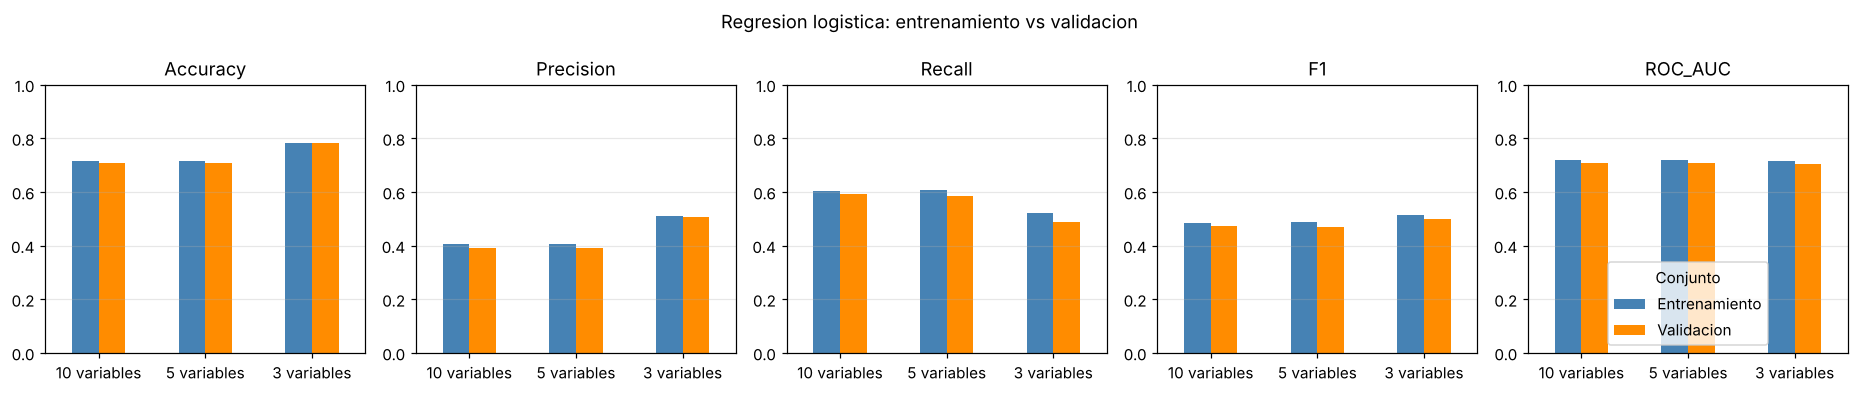

In [18]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.6))
for ax, met in zip(axes, metricas_c):
    piv = res_clf.pivot(index='Version', columns='Conjunto', values=met).loc[list(versiones_clf)]
    piv.plot(kind='bar', ax=ax, rot=0, color=['steelblue', 'darkorange'], legend=(met == 'ROC_AUC'))
    ax.set_title(met)
    ax.set_xlabel('')
    ax.set_ylim(0, 1)
    ax.grid(axis='y', alpha=0.3)
plt.suptitle('Regresion logistica: entrenamiento vs validacion')
plt.tight_layout()
plt.show()

In [19]:
coef_clf = pd.DataFrame({
    nombre: pd.Series(modelo[-1].coef_[0], index=versiones_clf[nombre])
    for nombre, modelo in modelos_clf.items()
}).loc[PREDICTORAS]
print('Coeficientes estandarizados (cambio en el log-odds de impago por una desviacion estandar):')
coef_clf

Coeficientes estandarizados (cambio en el log-odds de impago por una desviacion estandar):


,10 variables,5 variables,3 variables
SEX,-0.0614,NaN,NaN
EDUCATION,-0.0586,NaN,NaN
MARRIED,0.0847,NaN,NaN
AGE,0.0378,NaN,NaN
PAY_0,0.6146,0.6157,0.6006
PAY_2,0.2303,0.2256,0.1985
BILL_AMT1,-0.4194,-0.1970,NaN
BILL_AMT2,0.2285,NaN,NaN
PAY_AMT1,-0.1696,-0.1248,NaN
PAY_AMT2,-0.2457,-0.2452,-0.3970


## B.3 Evaluación en prueba de las dos mejores versiones

Elegimos las dos mejores versiones según el ROC-AUC de validación y, en caso de empate, desempatamos por F1. Igual que en la regresión, el conjunto de prueba se usa solo en este paso.

In [20]:
val_clf = res_clf[res_clf['Conjunto'] == 'Validacion'].set_index('Version')
mejores_clf = val_clf.sort_values(['ROC_AUC', 'F1'], ascending=False).index[:2].tolist()
print('Dos mejores versiones en validacion:', mejores_clf)

filas = []
for nombre in mejores_clf:
    cols = versiones_clf[nombre]
    prob = modelos_clf[nombre].predict_proba(X_test[cols])[:, 1]
    pred = (prob >= 0.5).astype(int)
    filas.append({'Version': nombre, **metricas_clasificacion(y2_test, pred, prob)})
test_clf = pd.DataFrame(filas).set_index('Version')
test_clf

Dos mejores versiones en validacion: ['5 variables', '10 variables']


,Accuracy,Precision,Recall,F1,ROC_AUC
Version,,,,,
5 variables,0.7102,0.3964,0.5914,0.4746,0.7080
10 variables,0.7093,0.3967,0.6014,0.4781,0.7148


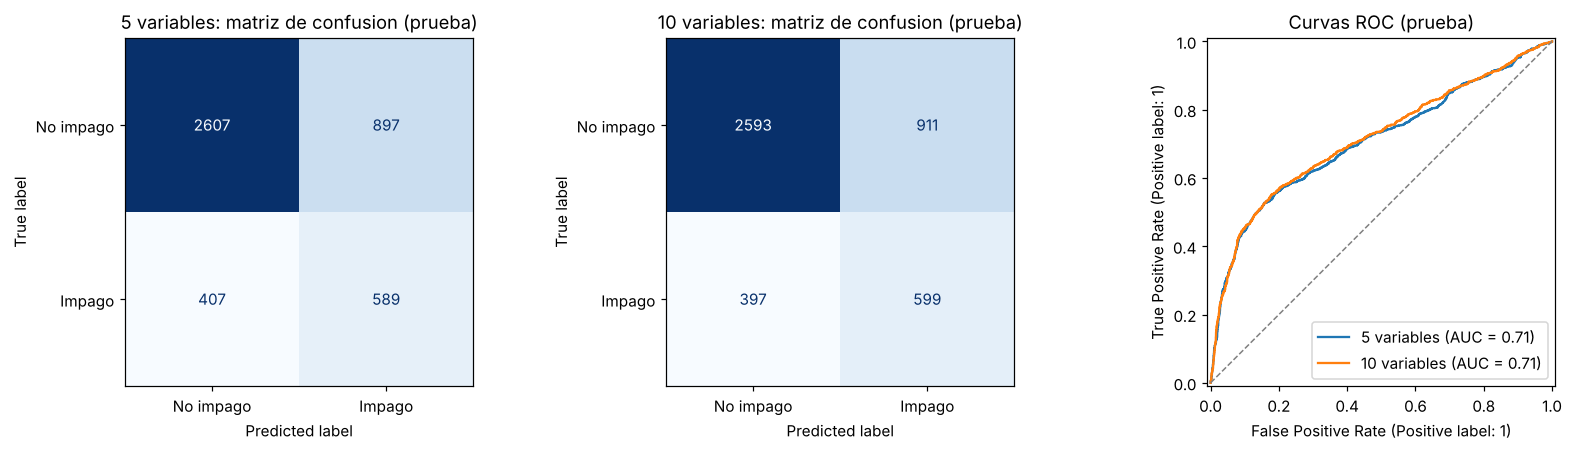

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, nombre in zip(axes[:2], mejores_clf):
    cols = versiones_clf[nombre]
    pred = modelos_clf[nombre].predict(X_test[cols])
    ConfusionMatrixDisplay(confusion_matrix(y2_test, pred),
                           display_labels=['No impago', 'Impago']).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'{nombre}: matriz de confusion (prueba)')

for nombre in mejores_clf:
    cols = versiones_clf[nombre]
    RocCurveDisplay.from_estimator(modelos_clf[nombre], X_test[cols], y2_test, ax=axes[2], name=nombre)
axes[2].plot([0, 1], [0, 1], ls='--', color='gray', lw=1)
axes[2].set_title('Curvas ROC (prueba)')
plt.tight_layout()
plt.show()

---
# Análisis: efecto de la cantidad de variables

Las versiones de 3, 5 y 10 variables son solo tres puntos de una curva más completa. Para ver esa curva, entrenamos un modelo para cada tamaño $k = 1, \dots, 10$ siguiendo el orden de *forward selection*, y lo medimos en entrenamiento y validación. Este análisis tampoco usa el conjunto de prueba.

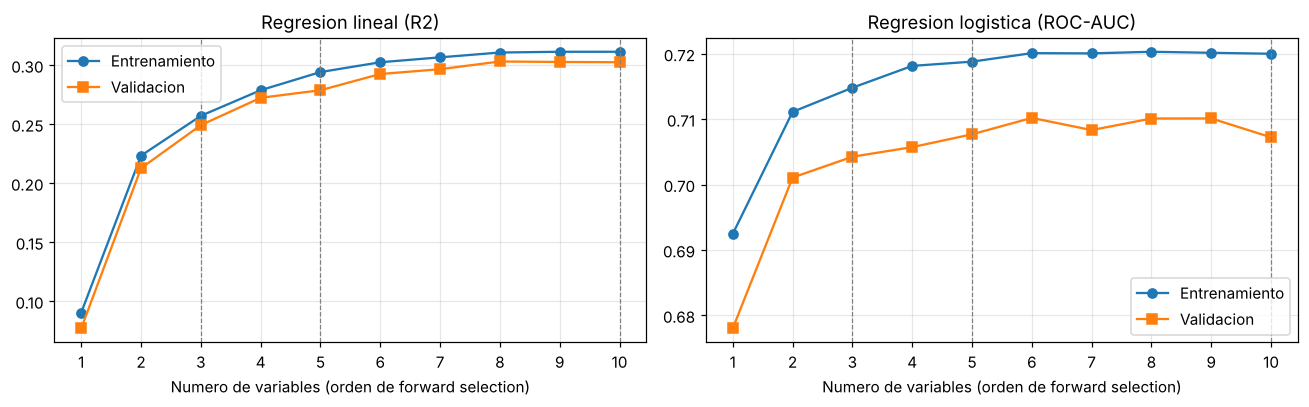

,R2 train,R2 val,AUC train,AUC val
k,,,,
1,0.0903,0.0769,0.6924,0.6780
2,0.2233,0.2127,0.7111,0.7011
3,0.2571,0.2492,0.7148,0.7043
4,0.2788,0.2723,0.7181,0.7057
5,0.2942,0.2788,0.7188,0.7077
6,0.3025,0.2925,0.7201,0.7102
7,0.3066,0.2966,0.7201,0.7083
8,0.3107,0.3031,0.7203,0.7101
9,0.3114,0.3027,0.7201,0.7101


In [22]:
curvas = []
for k in range(1, len(PREDICTORAS) + 1):
    cols_r = orden_reg[:k]
    m_r = crear_modelo_regresion().fit(X_train[cols_r], y1_train)
    cols_c = orden_clf[:k]
    m_c = crear_modelo_clasificacion().fit(X_train[cols_c], y2_train)
    curvas.append({
        'k': k,
        'R2 train': r2_score(y1_train, m_r.predict(X_train[cols_r])),
        'R2 val': r2_score(y1_val, m_r.predict(X_val[cols_r])),
        'AUC train': roc_auc_score(y2_train, m_c.predict_proba(X_train[cols_c])[:, 1]),
        'AUC val': roc_auc_score(y2_val, m_c.predict_proba(X_val[cols_c])[:, 1]),
    })
curvas = pd.DataFrame(curvas).set_index('k')

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (tr, va, titulo) in zip(axes, [('R2 train', 'R2 val', 'Regresion lineal (R2)'),
                                        ('AUC train', 'AUC val', 'Regresion logistica (ROC-AUC)')]):
    ax.plot(curvas.index, curvas[tr], marker='o', label='Entrenamiento')
    ax.plot(curvas.index, curvas[va], marker='s', label='Validacion')
    for k in (3, 5, 10):
        ax.axvline(k, color='gray', ls='--', lw=0.8)
    ax.set_xticks(curvas.index)
    ax.set_xlabel('Numero de variables (orden de forward selection)')
    ax.set_title(titulo)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()
curvas

## Resumen de resultados

La siguiente celda reúne en un solo lugar las cifras que se discuten más abajo: el $R^2$ y el ROC-AUC de cada versión en entrenamiento y validación, y el resultado en prueba de las dos mejores versiones de cada tarea.

In [23]:
def fila_resumen(tabla, metrica):
    return tabla[[(metrica, 'Entrenamiento'), (metrica, 'Validacion'), (metrica, 'Brecha (train - val)')]]

print('REGRESION LINEAL (Y1 = LIMIT_BAL)')
print(fila_resumen(tabla_reg, 'R2').round(4).to_string())
print('Mejores en validacion:', mejores_reg)
print(test_reg.round(4).to_string())
print()
print('REGRESION LOGISTICA (Y2 = DEFAULT)')
print(fila_resumen(tabla_clf, 'ROC_AUC').round(4).to_string())
print('Mejores en validacion:', mejores_clf)
print(test_clf.round(4).to_string())

REGRESION LINEAL (Y1 = LIMIT_BAL)
                        R2                                
Conjunto     Entrenamiento Validacion Brecha (train - val)
Version                                                   
10 variables        0.3114     0.3025               0.0089
5 variables         0.2942     0.2788               0.0154
3 variables         0.2571     0.2492               0.0079
Mejores en validacion: ['10 variables', '5 variables']
                     RMSE         MAE     R2
Version                                     
10 variables 109,059.2766 84,281.1953 0.3065
5 variables  111,187.5954 85,740.8201 0.2791

REGRESION LOGISTICA (Y2 = DEFAULT)
                   ROC_AUC                                
Conjunto     Entrenamiento Validacion Brecha (train - val)
Version                                                   
10 variables        0.7200     0.7072               0.0128
5 variables         0.7188     0.7077               0.0111
3 variables         0.7148     0.7043         

## Discusión

### Regresión lineal ($Y_1$ = `LIMIT_BAL`)

El $R^2$ es bajo en las tres versiones: 0,30 en validación con diez variables, 0,28 con cinco y 0,25 con tres. El modelo explica menos de un tercio de la variabilidad del cupo, lo que indica underfitting: un modelo lineal con estas variables no alcanza a capturar cómo el banco asigna los cupos.

Los gráficos de prueba lo confirman. La nube de puntos es más plana que la diagonal, es decir, el modelo comprime sus predicciones hacia el centro. Para el 10 % de clientes con mayor cupo predice en promedio cerca de 230.000, cuando el valor real promedio es cercano a 430.000, y en el otro extremo sobrestima los cupos bajos. Además predice cupos negativos para 37 clientes de prueba, algo imposible en la realidad, y genera unas pocas predicciones extremas, sobre 1.000.000, para clientes con montos de pago atípicos. Las franjas diagonales que aparecen en los residuos no son un error del modelo: se deben a que `LIMIT_BAL` toma valores redondos, múltiplos de 10.000.

La mejor versión en validación es la de diez variables, seguida de la de cinco, y esas dos son las que evaluamos en prueba. Pasar de diez a cinco variables cuesta 0,024 de $R^2$, y pasar de cinco a tres cuesta 0,030 más: con tres variables el modelo pierde información útil y el underfitting se acentúa. La selección sí detectó la redundancia que habíamos dejado a propósito. `BILL_AMT2` quedó en el último lugar del ranking y su coeficiente en el modelo de diez variables es prácticamente cero (1.338, frente a 43.077 de `BILL_AMT1`), lo que confirma que, una vez incluida `BILL_AMT1`, no agrega información.

No hay overfitting. La brecha entre entrenamiento y validación es de 0,01 a 0,02 puntos de $R^2$ en todas las versiones, y en prueba el $R^2$ es prácticamente igual al de validación (0,31 con diez variables y 0,28 con cinco). Esto era esperable: con 21.000 ejemplos de entrenamiento y a lo más 11 parámetros, un modelo lineal tiene muy poca capacidad para memorizar los datos.

### Regresión logística ($Y_2$ = `DEFAULT`)

El estado de pago más reciente, `PAY_0`, es por lejos la variable más relevante: por sí sola alcanza un ROC-AUC de 0,69 en validación cruzada, frente a 0,72 con todas las variables. Las que entran después aportan mejoras pequeñas, y las últimas no mejoran o incluso empeoran levemente el resultado. Por eso las tres versiones tienen un ROC-AUC muy parecido en validación, entre 0,704 y 0,708.

La mejor versión en validación fue la de cinco variables, seguida muy de cerca por la de diez, con una diferencia de 0,0005. En prueba el orden se invierte: 0,715 con diez variables y 0,708 con cinco. Esto merece una explicación, porque podría leerse como que la selección se equivocó. Lo que muestra en realidad es que la diferencia entre ambas versiones es menor que la variación propia de evaluar sobre muestras de 4.500 clientes. En la práctica rinden igual, y la de cinco variables es preferible por ser más simple.

Sobre overfitting hay solo una señal muy débil. En la curva de la sección anterior, el ROC-AUC de entrenamiento se mantiene estable al pasar de ocho a diez variables, mientras que el de validación baja un poco. La brecha entre entrenamiento y validación también crece levemente con el número de variables, de 0,011 con tres y cinco variables a 0,013 con diez. Esto sugiere que las últimas variables empiezan a ajustarse a particularidades del entrenamiento más que a información útil, pero la diferencia es demasiado pequeña para hablar de un overfitting relevante.

Las métricas que dependen del umbral cuentan una historia algo distinta, y conviene entender por qué. Como el modelo usa `class_weight='balanced'`, prioriza detectar impagos: el recall, cercano a 0,6, es mayor que la precision, cercana a 0,4. Es decir, detecta alrededor del 60 % de los clientes que caen en impago a costa de bastantes falsas alarmas. Por lo mismo, el accuracy de las versiones de cinco y diez variables (0,71) queda por debajo del 78 % que lograría el clasificador trivial, lo que muestra por qué no es una buena métrica en este problema.

La versión de tres variables, en cambio, tiene el mejor accuracy (0,78) y el mejor F1 (0,50) en validación, pese a tener el menor ROC-AUC. Sus probabilidades se distribuyen de otra forma, y el umbral fijo de 0,5 la deja en otro punto del compromiso entre precision y recall: marca a menos clientes como impago, gana precision y pierde recall. Por eso comparamos las versiones con ROC-AUC, que mide la capacidad de ordenar a los clientes por riesgo. El umbral se puede ajustar después según el costo de cada tipo de error.

En el modelo de diez variables, `BILL_AMT1` y `BILL_AMT2` tienen coeficientes de signo opuesto (-0,42 y 0,23). Es un efecto típico de la multicolinealidad: como las dos variables se mueven casi juntas, el modelo reparte su efecto entre ambas y los coeficientes individuales dejan de ser interpretables por separado.

Igual que en la regresión, la limitación principal es el underfitting. Una frontera de decisión lineal no captura bien relaciones como el efecto de `PAY_0`, cuyos valores -2, -1 y 0 representan situaciones distintas que no siguen una escala lineal.

### Conclusión sobre la cantidad de variables

Agregar variables mejora el desempeño solo mientras aportan información nueva. En ambas tareas las curvas se aplanan después de las primeras cinco o seis variables, y las restantes resultan redundantes o poco informativas.

Más variables no produjeron un overfitting relevante, porque los modelos lineales tienen poca capacidad y el conjunto de entrenamiento es grande. Solo en la regresión logística aparece una señal muy débil al agregar las últimas. La conclusión no es que el overfitting no importe, sino que en este caso no es el problema. Sería un riesgo real con modelos mucho más flexibles, por ejemplo con muchas interacciones o términos polinomiales, o con pocos datos, y ahí sí convendría una regularización más fuerte (clase 14) o una selección de variables más agresiva.

El problema dominante es el underfitting, sobre todo en la regresión. Para mejorar habría que darle más capacidad al modelo, con transformaciones como el logaritmo de los montos, codificación one-hot de `PAY_0` o interacciones, más que agregar o quitar variables.

La mejor elección depende de la tarea. En la regresión, las variables adicionales sí aportan y conviene usar las diez. En la clasificación, la versión de cinco variables rinde igual que la de diez con un modelo más simple e interpretable.